In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

In [3]:
wine = load_wine()
X = pd.DataFrame(wine.data, columns=wine.feature_names)
y = pd.Series(wine.target, name="target")

# Розділення на навчальну і тестову вибірки (80/20)
# Важливо: ділимо до масштабування, щоб уникнути витоку даних (data leakage)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Масштабування ознак
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

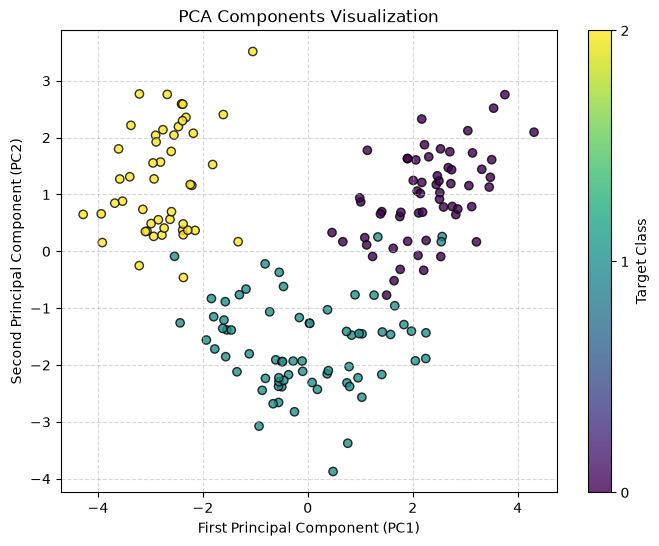

In [4]:
pca_2 = PCA(n_components=2)
# Для візуалізації трансформуємо всі масштабовані дані
X_all_scaled = scaler.fit_transform(X)
X_pca_2 = pca_2.fit_transform(X_all_scaled)

# Побудова scatter-графіка
plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    X_pca_2[:, 0], 
    X_pca_2[:, 1], 
    c=y, 
    cmap='viridis', 
    edgecolor='k', 
    alpha=0.8
)
plt.xlabel("First Principal Component (PC1)")
plt.ylabel("Second Principal Component (PC2)")
plt.title("PCA Components Visualization")
plt.colorbar(scatter, ticks=[0, 1, 2], label="Target Class")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

In [5]:
components_list = [2, 5, 10]
accuracies = []

print("--- Результати оцінки точності ---")
for n in components_list:
    # Зниження розмірності через PCA
    pca = PCA(n_components=n, random_state=42)
    X_train_pca = pca.fit_transform(X_train_scaled)
    X_test_pca = pca.transform(X_test_scaled)
    
    # Навчання логістичної регресії
    model = LogisticRegression(random_state=42)
    model.fit(X_train_pca, y_train)
    
    # Оцінка якості на тесті
    y_pred = model.predict(X_test_pca)
    acc = accuracy_score(y_test, y_pred)
    accuracies.append(acc)
    
    print(f"Кількість компонент: {n:2d} | Accuracy: {acc:.4f}")

--- Результати оцінки точності ---
Кількість компонент:  2 | Accuracy: 0.9167
Кількість компонент:  5 | Accuracy: 0.9722
Кількість компонент: 10 | Accuracy: 0.9722


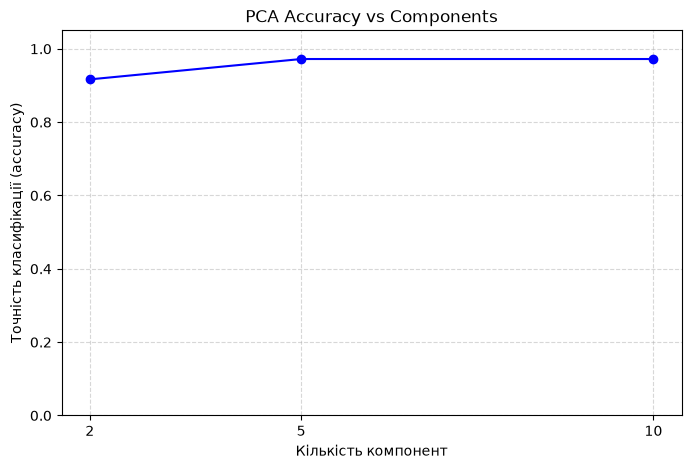

In [6]:
plt.figure(figsize=(8, 5))
plt.plot(components_list, accuracies, marker='o', linestyle='-', color='b')
plt.xlabel("Кількість компонент")
plt.ylabel("Точність класифікації (accuracy)")
plt.title("PCA Accuracy vs Components")
plt.xticks(components_list)
plt.ylim(0, 1.05)
plt.grid(True, linestyle="--", alpha=0.5)

# Збереження графіку
plt.savefig("pca_accuracy_results.png", dpi=300, bbox_inches='tight')
plt.show()